# Notebook 16: Master Empirical Benchmark — Centralized vs Isolated vs FedAvg vs FedProx

## 1. Honest End-to-End Comparison
All figures below are loaded directly from `ml/artifacts/federated_benchmark.json` (Leave-Last-2-Out chronological ranking against 99 unobserved negatives).

In [1]:
import os, sys, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Resolve repository root deterministically from ml/notebooks/
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

DATA_DIR = os.path.join(REPO_ROOT, "ml", "data", "processed")
ARTIFACTS_DIR = os.path.join(REPO_ROOT, "ml", "artifacts")
VIZ_DIR = os.path.join(REPO_ROOT, "ml", "visualizations")
plt.rcParams["figure.dpi"] = 110
with open(os.path.join(ARTIFACTS_DIR, "federated_benchmark.json"), "r") as f:
    bench = json.load(f)

rows = [
    {"Paradigm": "Centralized Gold", "NDCG@10": bench["centralized_baseline"]["ndcg10"], "HR@10": bench["centralized_baseline"]["hr10"], "MRR": bench["centralized_baseline"]["mrr"], "Parity_%": 100.0, "Privacy": bench["centralized_baseline"]["privacy_guarantee"]},
    {"Paradigm": "Isolated Local", "NDCG@10": bench["isolated_local"]["ndcg10"], "HR@10": bench["isolated_local"]["hr10"], "MRR": bench["isolated_local"]["mrr"], "Parity_%": bench["isolated_local"]["parity_pct"], "Privacy": bench["isolated_local"]["privacy_guarantee"]},
    {"Paradigm": "FedAvg (Non-IID)", "NDCG@10": bench["fedavg_non_iid"]["ndcg10"], "HR@10": bench["fedavg_non_iid"]["hr10"], "MRR": bench["fedavg_non_iid"]["mrr"], "Parity_%": bench["fedavg_non_iid"]["parity_pct"], "Privacy": bench["fedavg_non_iid"]["privacy_guarantee"]},
    {"Paradigm": "FedProx (mu=0.01)", "NDCG@10": bench["fedprox_non_iid"]["ndcg10"], "HR@10": bench["fedprox_non_iid"]["hr10"], "MRR": bench["fedprox_non_iid"]["mrr"], "Parity_%": bench["fedprox_non_iid"]["parity_pct"], "Privacy": bench["fedprox_non_iid"]["privacy_guarantee"]},
]
df_bench = pd.DataFrame(rows)
print(df_bench.round(4).to_string(index=False))

         Paradigm  NDCG@10  HR@10    MRR  Parity_%                                     Privacy
 Centralized Gold   0.1061 0.2400 0.0926  100.0000       Centralized Leakage (Raw logs stored)
   Isolated Local   0.0898 0.2057 0.0841   84.6735    0 Bytes Leakage (Severe Data Starvation)
 FedAvg (Non-IID)   0.0500 0.1232 0.0615   47.0984 0 Bytes User Leakage (Item Projection Sync)
FedProx (mu=0.01)   0.0742 0.1551 0.0825   69.9014 0 Bytes User Leakage (Item Projection Sync)


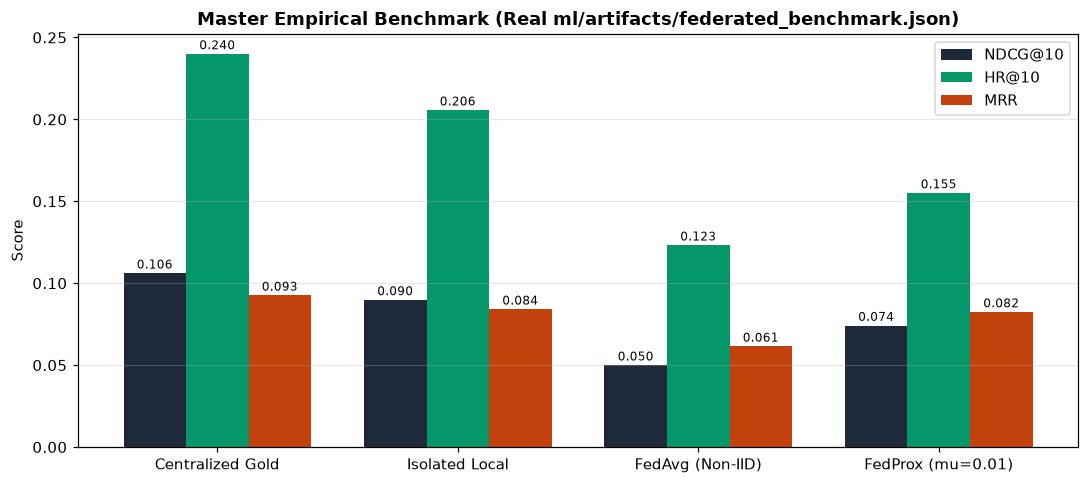

In [2]:
x = np.arange(len(df_bench))
width = 0.26
fig, ax = plt.subplots(figsize=(10, 4.5))
b1 = ax.bar(x - width, df_bench["NDCG@10"], width, label="NDCG@10", color="#1e293b")
b2 = ax.bar(x, df_bench["HR@10"], width, label="HR@10", color="#059669")
b3 = ax.bar(x + width, df_bench["MRR"], width, label="MRR", color="#c2410c")
ax.set_xticks(x)
ax.set_xticklabels(df_bench["Paradigm"])
ax.set_ylabel("Score")
ax.set_title("Master Empirical Benchmark (Real ml/artifacts/federated_benchmark.json)", fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.3)
for bars in (b1, b2, b3):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.3f}", (bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
plt.tight_layout()
plt.show()